##### Resume

In this laboratory v3 we are going to make use of a Logistic Regression Model, note that we no longer use Glucose as our target value, instead, we are 
using it as a new feature with skin thickness, insulin, preganancies and diabetes pedigree function.

Our new target value is Outcome wich denotes if a patient is 1 = diabetic, or 0 = not diabetic

In [9]:
import copy, math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the diabetes dataset
dt = pd.read_csv('diabetes.csv')

# Before cleaning the dataset, print the shape and types of the original DataFrame
X_train = dt[['BMI', 'Age', 'BloodPressure', 'Insulin', 'SkinThickness', 'Pregnancies', 'DiabetesPedigreeFunction', 'Glucose']].to_numpy()
y_train = dt['Outcome'].to_numpy()
print(f"X Shape before cleaning: {X_train.shape}, X Type before cleaning:{type(X_train)})")
print(f"y Shape before cleaning: {y_train.shape}, y Type before cleaning:{type(y_train)})")

# Clean the dataset by removing rows with zero values in BMI, Glucose, Age, and BloodPressure
df_clean = dt[(dt['BMI'] != 0) & (dt['Glucose'] != 0) & (dt['Age'] != 0) & (dt['BloodPressure'] != 0) & (dt['Insulin'] != 0) & (dt['SkinThickness'] != 0) & (dt['Pregnancies'] != 0)
              & (dt['DiabetesPedigreeFunction'] != 0)]

# Transform the cleaned DataFrame into NumPy arrays for features and target variable
X_train = df_clean[['BMI', 'Age', 'BloodPressure', 'Insulin', 'SkinThickness', 'Pregnancies', 'DiabetesPedigreeFunction', 'Glucose']].to_numpy()
y_train = df_clean['Outcome'].to_numpy()

# Print the shapes and types of the feature and target arrays
print(f"X Shape after cleaning: {X_train.shape}, X Type:{type(X_train)})")
print(f"y Shape after cleaning: {y_train.shape}, y Type:{type(y_train)})")

# We lost almost half of the data after cleaning because of Insulin and SkinThickness having a lot of zero values

X Shape before cleaning: (768, 8), X Type before cleaning:<class 'numpy.ndarray'>)
y Shape before cleaning: (768,), y Type before cleaning:<class 'numpy.ndarray'>)
X Shape after cleaning: (336, 8), X Type:<class 'numpy.ndarray'>)
y Shape after cleaning: (336,), y Type:<class 'numpy.ndarray'>)


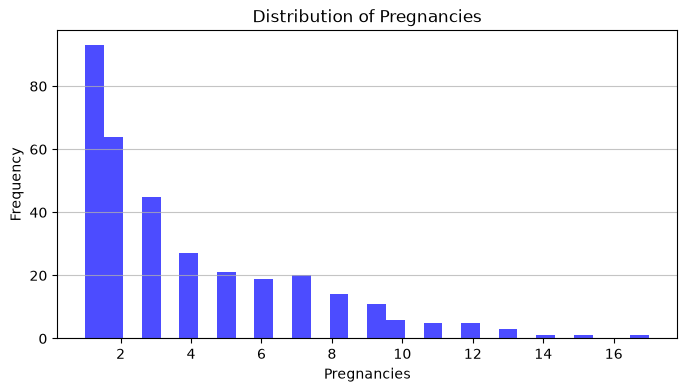

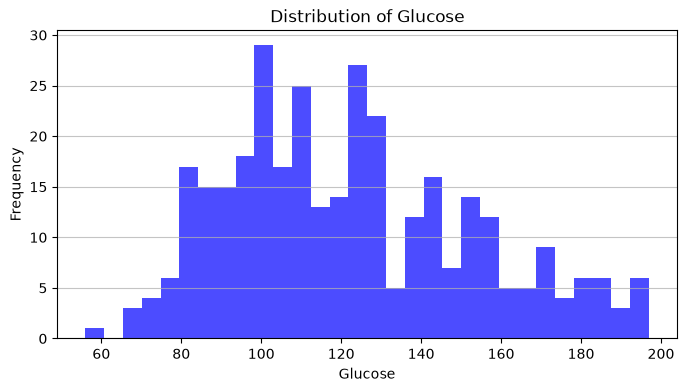

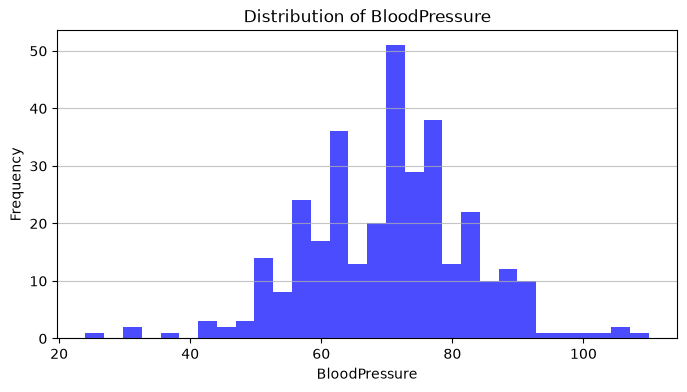

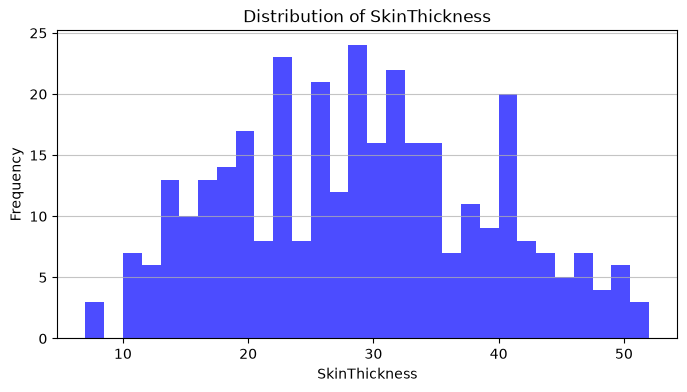

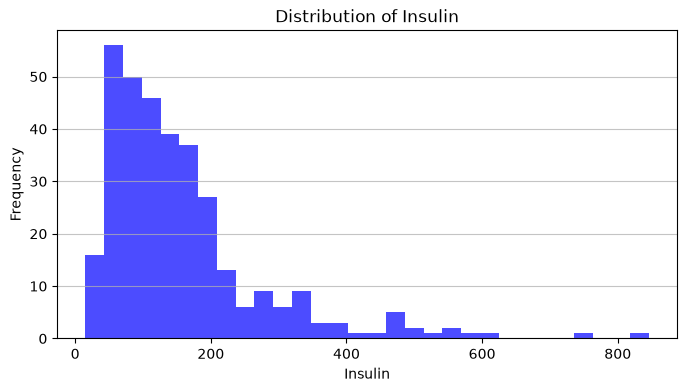

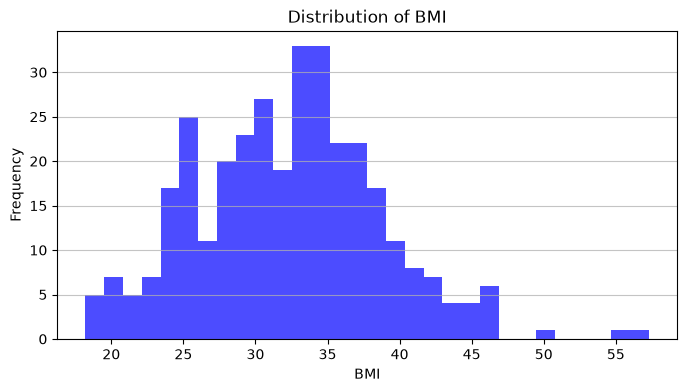

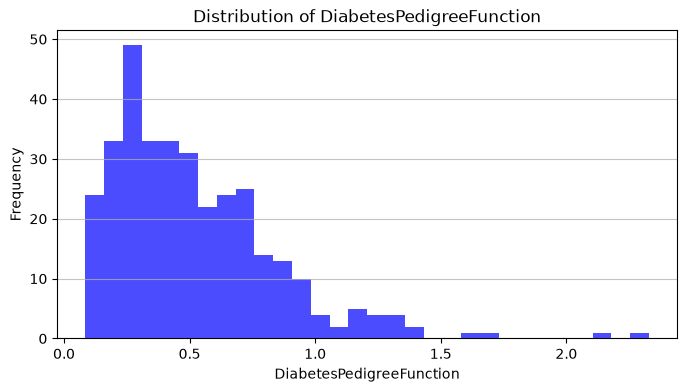

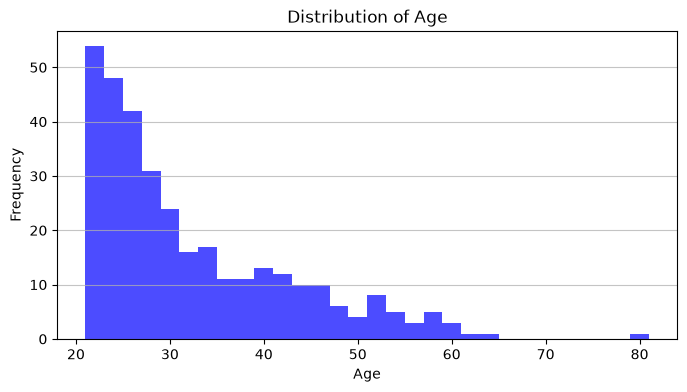

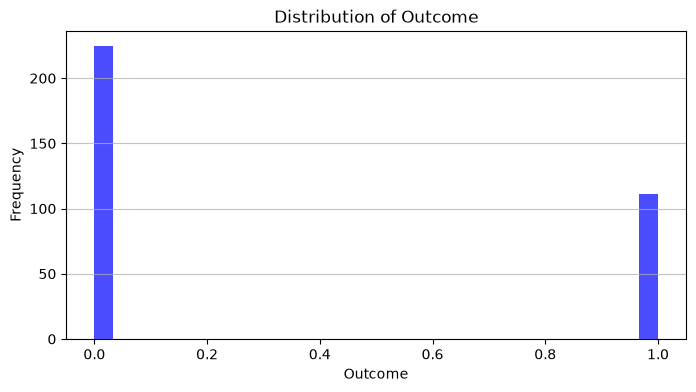

In [4]:
# Plot the distribution of the features to see if we can identify any patterns or outliers

for col in df_clean.columns:
    plt.figure(figsize=(8, 4))
    plt.hist(df_clean[col], bins=30, alpha=0.7, color='blue')
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.grid(axis='y', alpha=0.75)
    plt.show()

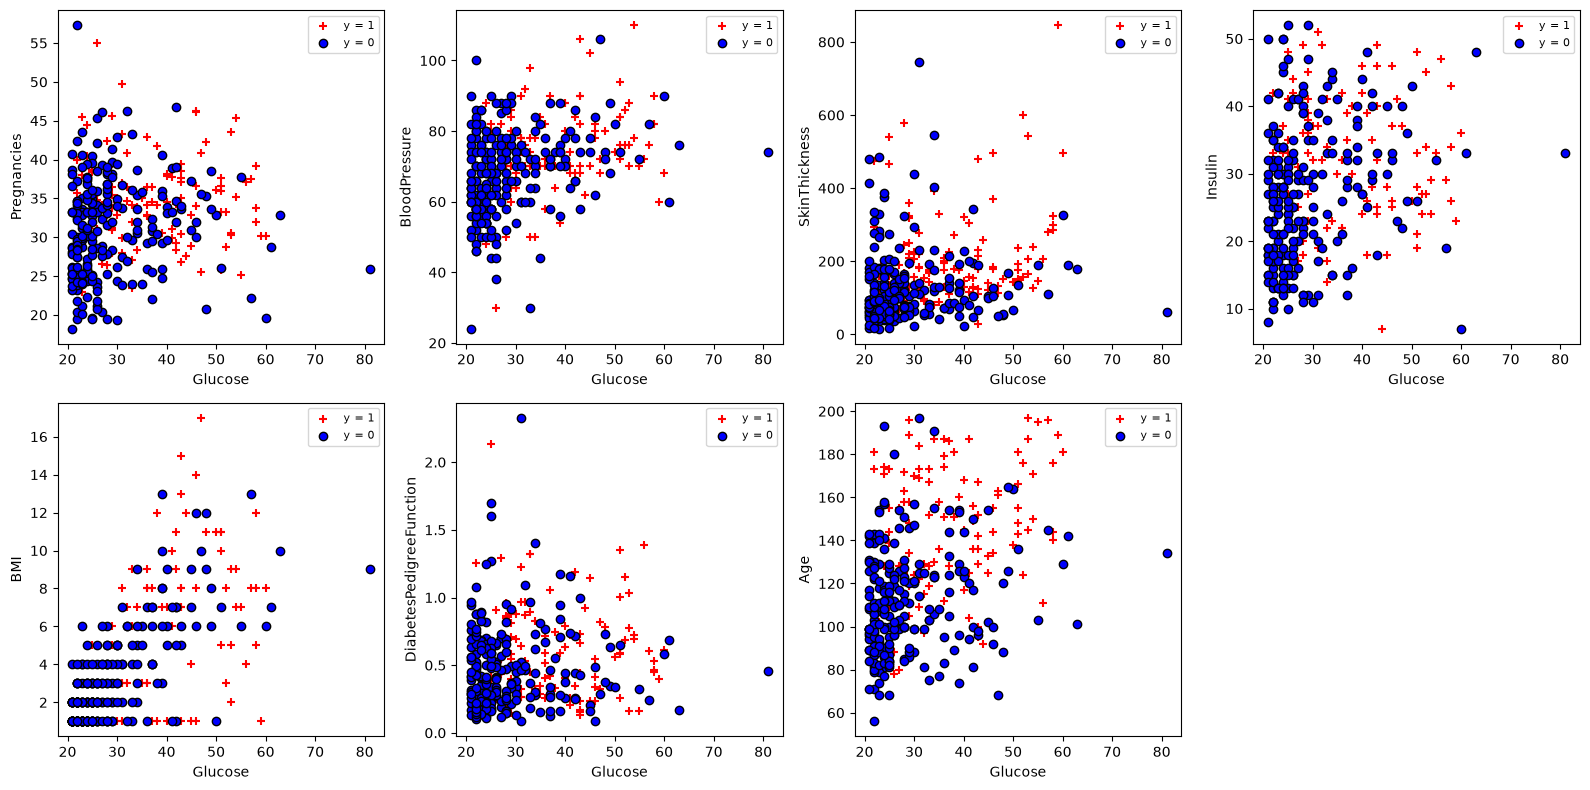

In [16]:
# The cleaned dataset has a uniform distribution of values across the features and also lacks of outliers, this should help the model to generalize better and avoid overfitting

# Plot our 8 features against each other to see if we can identify any patterns or relationships between them

features = ['Pregnancies','Glucose','BloodPressure','SkinThickness',
            'Insulin','BMI','DiabetesPedigreeFunction','Age']
g = features.index('Glucose')
pairs = [f for f in features if f != 'Glucose']
fig, ax = plt.subplots(2, 4, figsize=(16, 8))
for k, f in enumerate(pairs):
    j = features.index(f); a = ax[k // 4, k % 4]
    a.scatter(X_train[y_train==1, g], X_train[y_train==1, j], c='r', marker='+', label='y = 1')
    a.scatter(X_train[y_train==0, g], X_train[y_train==0, j], c='b', marker='o', edgecolors='k', label='y = 0')
    a.set_xlabel('Glucose'); a.set_ylabel(f); a.legend(fontsize=8)
ax[1, 3].axis('off')
plt.tight_layout(); plt.show()